# Stage 2 (Twitter-only, seed 42): NER on WNUT17 with CRF, SVM and an improved Bi-LSTM CRF
**Kelompok 1, Pemrosesan Bahasa Alami Lanjut, UGM.**

What is different from the first Stage 2 run
* **Training data = the Twitter train file only.** The YouTube dev file is used only to choose settings and stop training; it never updates any weight.
* **Seed 42** for every run.
* Several ways to raise the Bi-LSTM CRF F1 are tried (word dropout, fine-tuned GloVe, larger hidden layer, POS-tag input, a precision-recall shift at decoding, and an ensemble). Every choice is made on dev; test scores of the steps are shown for transparency only.

How to use it: with `RUN_TRAINING = False` (default) the notebook reloads the saved predictions and results and recomputes every table and figure in about a minute. With `RUN_TRAINING = True` it retrains everything (needs the GloVe file, see `prep_glove.py`; about one hour on a laptop CPU).

In [1]:
# ---- Setup: locate code, results and the official WNUT17 files ----
import os, sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")
HERE = Path.cwd()
CODE_DIR = next(p for p in [HERE, HERE / "kode", HERE.parent / "kode"] if (p / "wnut_data.py").exists())
RESULTS = Path(os.environ["NB_RESULTS"]) if "NB_RESULTS" in os.environ else next(p for p in [HERE / "results", CODE_DIR.parent / "results", CODE_DIR / "results"] if p.exists())
WNUT_DIR = next((p for p in [HERE / "data", CODE_DIR.parent / "data", CODE_DIR / "data", Path("/home/claude/emerging_entities_17")] if (p / "wnut17train.conll").exists()), None)
assert WNUT_DIR is not None, "Put wnut17train.conll, emerging.dev.conll and emerging.test.annotated in a folder called data/"
os.environ["WNUT_DIR"] = str(WNUT_DIR); sys.path.insert(0, str(CODE_DIR)); os.chdir(CODE_DIR)
RUN_TRAINING = False          # True = retrain every model (slow)
SEED = 42                     # the only seed used
print("code:", CODE_DIR, "| results:", RESULTS, "| data:", WNUT_DIR)

code: /home/claude/proj | results: /home/claude/proj/results | data: /home/claude/emerging_entities_17


## 1. Data loading and checks
Official splits, no re-splitting: `wnut17train.conll` (Twitter 2010, **the only training data**), `emerging.dev.conll` (YouTube, tuning and stopping only), `emerging.test.annotated` (Reddit, StackExchange, Twitter 2017; the gold test file scored once).
The repository file `emerging.test.conll` holds raw multi-annotator labels and is **not** used. A blank line ends a document; a tab-only line ends a sentence inside a train tweet.

In [2]:
from wnut_data import load
from seqeval.metrics.sequence_labeling import get_entities
splits = {s: load(s) for s in ["train", "dev", "test"]}     # items: {"tokens": [...], "labels": [...], "doc": id}

def bio_violations(seqs):
    """Count I-X labels that are not preceded by B-X or I-X (an invalid IOB2 sequence)."""
    bad = 0
    for x in seqs:
        prev = "O"
        for l in x["labels"]:
            if l.startswith("I-") and prev not in ("B-" + l[2:], "I-" + l[2:]): bad += 1
            prev = l
    return bad
rows = []
for s, seqs in splits.items():
    labels = [l for x in seqs for l in x["labels"]]
    rows.append(dict(split=s, sequences=len(seqs), tokens=len(labels), entities=sum(len(get_entities(x["labels"])) for x in seqs), pct_O=round(100 * labels.count("O") / len(labels), 1), max_len=max(len(x["tokens"]) for x in seqs), bio_violations=bio_violations(seqs)))
stats = pd.DataFrame(rows).set_index("split"); display(stats)
assert stats["sequences"].tolist() == [3394, 1009, 1287] and stats["tokens"].tolist() == [62730, 15733, 23394] and stats["entities"].tolist() == [1975, 836, 1079] and stats["bio_violations"].sum() == 0
print("Stage 1 counts reproduced. Training data: the", stats.loc["train", "sequences"], "Twitter sequences only.")

,sequences,tokens,entities,pct_O,max_len,bio_violations
split,,,,,,
train,3394,62730,1975,95.0,41,0
dev,1009,15733,836,92.1,82,0
test,1287,23394,1079,92.6,105,0


Stage 1 counts reproduced. Training data: the 3394 Twitter sequences only.


## 2. Preprocessing
Tokens are used as released. A **normalized copy** is used for embedding lookup and lexical features: HTML unescape, NFKC, URL (including bare domains) to `<URL>`, `@user` to `<USER>`, hashtag `#` dropped, every digit to `0`, a repeated character capped at 3 (digit runs are **not** capped), lowercase. No stemming, lemmatization or stop-word removal.

In [3]:
from prep_glove import normalize, glove_keys
examples = ["2017", "12,000", "soooooo", "!!!!!!!", "&amp;", "@paulwalk", "http://t.co/x", "amazon.com", "#Ravens", "THANK"]
display(pd.DataFrame({"token": examples, "normalized": [normalize(t) for t in examples], "GloVe lookup keys": [glove_keys(t) for t in examples]}))
# Regression tests for the three normalization bugs fixed after the first Stage 2 run
assert normalize("2017") == "0000" and normalize("amazon.com") == "<URL>" and normalize("#Ravens") == "ravens"
assert normalize("soooooo") == "sooo" and normalize("&amp;") == "&" and normalize("@paulwalk") == "<USER>"

,token,normalized,GloVe lookup keys
0,2017,0000,"[2017, 0000, <number>]"
1,"12,000","00,000","[12,000, 00,000, <number>]"
2,soooooo,sooo,"[soooooo, sooo]"
3,!!!!!!!,!!!,"[!!!!!!!, !!!]"
4,&amp;,&,"[&amp;, &]"
5,@paulwalk,<USER>,[<user>]
6,http://t.co/x,<URL>,[<url>]
7,amazon.com,<URL>,[<url>]
8,#Ravens,ravens,"[#ravens, ravens, ravens]"
9,THANK,thank,"[thank, thank]"


## 3. Features for the CRF and SVM
Per token: lexical (lowercase, normalized, stop-word flag), context words at -2..+2 with bigrams and BOS/EOS, prefixes and suffixes of 1 to 4 characters, shape, social-media flags, NLTK POS tags, and K-Means cluster IDs of GloVe vectors (needs the GloVe file, so it is skipped in this demo).
**Capitalization:** the original-case token feeds the shape and `is_title` features, so *Google* and *google* differ there; everything lexical is lowercased and GloVe Twitter is uncased.

In [4]:
import nltk
from features import sent_feats
try: nltk.pos_tag(["test"])
except LookupError: nltk.download("averaged_perceptron_tagger_eng", quiet=True)
sent = splits["test"][6]; pos = [t for _, t in nltk.pos_tag(sent["tokens"])]
feats = sent_feats(sent["tokens"], pos, ["word", "shape", "affix", "social", "context", "pos"]); i = sent["tokens"].index("Gurez")
print(" ".join(sent["tokens"]), "\ntoken:", sent["tokens"][i], "| gold:", sent["labels"][i], "| features:", len(feats[i]))
display(pd.Series({k: v for k, v in feats[i].items() if k in ["w.lower", "w.norm", "w.shape", "w.title", "pre3", "suf3", "pos", "w-1", "w+1", "bi-1"]}).to_frame("value"))

Visuals of the avalanche site in Gurez sector . 
token: Gurez | gold: B-location | features: 35


,value
w.lower,gurez
w.norm,gurez
w.shape,Xx
w.title,True
pre3,gur
suf3,rez
pos,NNP
w-1,in
w+1,sector
bi-1,in|gurez


## 4. Models (all trained on the train file only, seed 42)
| Model | Implementation | Settings (chosen on dev) |
|---|---|---|
| CRF | `sklearn-crfsuite`, L-BFGS | full features, c1 = 0.3, c2 = 0.003, 300 iterations |
| SVM | `sklearn` LinearSVC | C = 0.03, balanced class weights, GloVe vector appended, no BIO repair |
| Bi-LSTM CRF (baseline) | JAX + optax, `bilstm_crf.py` | frozen GloVe Twitter 200d + char-CNN + capitalization embedding, 128 units per direction, dropout 0.5, Adam 1e-3, batch 32 |
| Bi-LSTM CRF (ensemble) | `ensemble_bilstm.py` | average of the six seed-42 variants V0 to V5 (Section 5), no decoding shift |

In [5]:
if RUN_TRAINING:
    import subprocess
    for script in ["prep_glove.py", "trainonly_models.py", "improve_bilstm.py", "ensemble_bilstm.py", "analysis_to.py", "make_figures_to.py"]:
        print("running", script); subprocess.run([sys.executable, script], check=True)
else:
    print("RUN_TRAINING = False: using the saved results in", RESULTS)

RUN_TRAINING = False: using the saved results in /home/claude/proj/results


In [6]:
# The Bi-LSTM CRF options added for the improvement study (word dropout, fine-tuned embeddings, POS input, O-bias decoding), printed from the source.
import inspect
try:
    import bilstm_crf
    print(inspect.getsource(bilstm_crf.emissions)); print(inspect.getsource(bilstm_crf.make_fns))
except ImportError as e:
    print("JAX/optax not installed here (", e, "). Open bilstm_crf.py to read the model code.")

def emissions(params, E, W, C, CP, M, key, train, drop, wdrop=0.0):
    """Label scores per token: [GloVe | char-CNN | capitalization] -> dropout -> Bi-LSTM -> dropout -> linear layer."""
    we = E[W]                                              # (B,T,200)
    if train and wdrop > 0: we = we * jax.random.bernoulli(jax.random.fold_in(key, 11), 1 - wdrop, (we.shape[0], we.shape[1], 1))   # word dropout: zero the GloVe vector, like a word without a vector
    ce = params["char_emb"][C]                             # (B,T,Lw,Ce)
    Lw = ce.shape[2]; cpad = jnp.pad(ce, ((0, 0), (0, 0), (1, 1), (0, 0)))
    conv = sum(jnp.einsum("btlc,cf->btlf", cpad[:, :, k:k + Lw], params["conv_w"][k]) for k in range(3)) + params["conv_b"]
    conv = jnp.where((C > 0)[..., None], jax.nn.relu(conv), -1e9)
    cf = jnp.max(conv, axis=2); cf = jnp.where(cf < -1e8, 0.0, cf)
    if "pos_emb" in params: x = jnp.concatenate([we, cf, params["cap_emb"][CP % N_CAP], params["pos_emb"][CP // N_CAP]], -1)
    else: x

## 5. Improving the Bi-LSTM CRF (chosen on dev only)
Each variant is trained on train (seed 42), stopped on dev (patience 8, at most 35 epochs), and compared on **dev** F1. Test F1 is printed for transparency but never used to choose.
1. **V1 word dropout:** the GloVe vector of 10% of the tokens is zeroed during training, like a word without a vector (15% of test entity tokens have none, against 6% in train).
2. **V2 fine-tuned GloVe:** the vector table is trainable with a 10x smaller effective learning rate.
3. **V3 hidden size 256.**  4. **V4 POS-tag embedding** (NLTK tags, 12 dims).
5. **V5 combination:** every single change that gained at least 0.3 dev F1, together (rule fixed in advance).
6. **Decoding shift:** a constant delta is subtracted from the O score before Viterbi; delta is chosen on dev.
7. **Ensemble (defined before its scores were seen):** average the emission and CRF scores of V0 to V5, then decode.

What to look for in the tables below: gains on dev did not carry over to test for the single changes and for the shift; only the ensemble rose on both.

,variant,best epoch,dev F1,dev gain,test F1 (not used to choose),kept by rule
0,V0 baseline (Twitter only),23,51.53,0.00,40.10,False
1,V1 word dropout 0.1,21,52.30,0.77,39.76,True
2,V2 fine-tuned GloVe (learning rate x0.1),21,51.95,0.42,39.36,True
3,V3 hidden size 256,26,53.41,1.88,37.85,True
4,V4 POS-tag input,31,52.21,0.68,39.64,True
5,V5 combination: V1 + V2 + V3 + V4,14,52.69,1.16,40.50,False


rule: keep every single change that gains at least 0.3 F1 on dev; combine them if there are two or more
single model with the best dev F1: V3 hidden size 256


dev P  dev R  dev F1  test F1
model    delta                               
ensemble 0.0    68.92  42.70   52.73    41.47
         0.5    66.15  45.81   54.13    42.29
         1.0    64.32  49.16   55.73    41.57
         1.5    61.22  51.56   55.97    40.41
         2.0    57.25  52.87   54.98    38.83
         2.5    51.99  53.23   52.60    36.72
         3.0    47.13  53.11   49.94    34.49

ensemble: dev F1 at delta 0 = 52.73 | best single dev F1 = 53.41 | delta chosen on dev: 1.5


dev P  dev R  dev F1  test F1
model    delta                               
baseline 0.0    66.10  42.22   51.53    40.10
         0.5    64.29  45.22   53.09    39.98
         1.0    62.54  47.73   54.14    39.18
         1.5    57.20  49.88   53.29    38.13
         2.0    52.91  52.15   52.53    36.02
         2.5    50.00  53.11   51.51    33.17
         3.0    42.96  51.44   46.82    30.36

baseline delta chosen on dev: 1.0


dev P  dev R  dev F1  test F1
model delta                               
final 0.0    66.79  44.50   53.41    37.85
      0.5    63.70  47.01   54.09    38.42
      1.0    60.38  49.40   54.34    37.85
      1.5    56.78  50.12   53.24    37.40
      2.0    54.22  52.27   53.23    36.48
      2.5    50.98  52.63   51.80    35.34
      3.0    46.71  52.63   49.49    33.88

final delta chosen on dev: 1.0


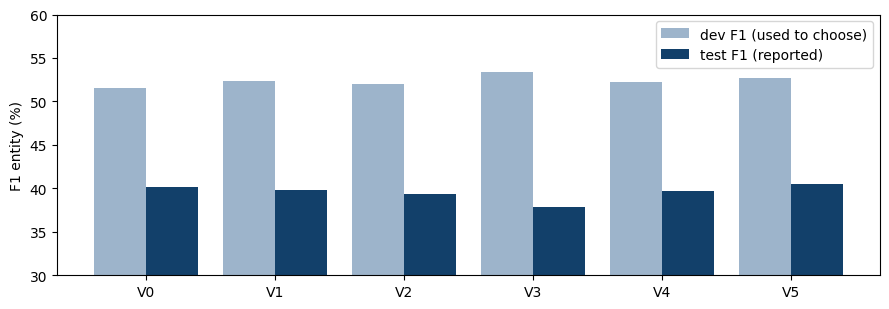

In [7]:
IB = json.load(open(RESULTS / "improve_bilstm.json"))
V = IB["variants"]; v0 = V[0]
ladder = pd.DataFrame([{"variant": v["name"], "best epoch": v["best_epoch"], "dev F1": v["dev_F1"], "dev gain": round(v["dev_F1"] - v0["dev_F1"], 2), "test F1 (not used to choose)": v["test"]["F1"], "kept by rule": v["name"] in IB["winners"]} for v in V])
display(ladder)
print("rule:", IB["combination_rule"]); print("single model with the best dev F1:", IB["final_variant"])
IBE = json.load(open(RESULTS / "ensemble_bilstm.json")); display(pd.DataFrame([{"delta": r["delta"], "dev P": r["dev"]["P"], "dev R": r["dev"]["R"], "dev F1": r["dev"]["F1"], "test F1": r["test"]["F1"]} for r in IBE["rows"]]).assign(model="ensemble").set_index(["model", "delta"]))
print("ensemble: dev F1 at delta 0 =", IBE["dev_delta0"], "| best single dev F1 =", IBE["best_single_dev_delta0"], "| delta chosen on dev:", IBE["best_delta"])
fin, base = IB["final"], IB["base"]
for tag, d in (("baseline", base), ("final", fin)):
    sw = IB["sweep"][d["variant"]]["rows"]; display(pd.DataFrame([{"delta": r["delta"], "dev P": r["dev"]["P"], "dev R": r["dev"]["R"], "dev F1": r["dev"]["F1"], "test F1": r["test"]["F1"]} for r in sw]).assign(model=tag).set_index(["model", "delta"]))
    print(tag, "delta chosen on dev:", d["delta"])
fig, ax = plt.subplots(figsize=(9, 3.2)); x = np.arange(len(V)); ax.bar(x - 0.2, [v["dev_F1"] for v in V], 0.4, label="dev F1 (used to choose)", color="#9DB4CB"); ax.bar(x + 0.2, [v["test"]["F1"] for v in V], 0.4, label="test F1 (reported)", color="#12406A")
ax.set_xticks(x); ax.set_xticklabels([v["name"][:2] for v in V]); ax.set_ylim(30, 60); ax.legend(); ax.set_ylabel("F1 entity (%)"); plt.tight_layout(); plt.show()

## 6. Evaluation on the test set
Strict entity-level precision, recall and F1 (`seqeval`, IOB2), shared-task surface F1 and token accuracy. Seed 42 for every model; the Bi-LSTM CRF ensemble averages the six seed-42 variants (no decoding shift).

In [8]:
from evalx import evaluate, error_breakdown, type_confusion
PRED_FILES = {"CRF": "pred_to_crf_test.json", "SVM": "pred_to_svm_test.json", "Bi-LSTM CRF (baseline)": "pred_to_bilstm_base_nobias_test.json", "Bi-LSTM CRF (ensemble)": "pred_to_bilstm_ens_nobias_test.json"}
preds = {m: json.load(open(RESULTS / f)) for m, f in PRED_FILES.items()}; test = splits["test"]; MODELS = list(preds)
assert all(len(p) == len(test) and all(len(a) == len(b["tokens"]) for a, b in zip(p, test)) for p in preds.values())   # aligned with the gold file
res = {m: evaluate(test, p) for m, p in preds.items()}
main = pd.DataFrame({m: {"Precision": 100 * r["entity"]["precision"], "Recall": 100 * r["entity"]["recall"], "F1 entity": 100 * r["entity"]["f1"], "F1 surface": 100 * r["surface"]["f1"], "Token accuracy": 100 * r["token_acc"]} for m, r in res.items()}).T.round(1)
display(main)

,Precision,Recall,F1 entity,F1 surface,Token accuracy
CRF,31.9,11.4,16.8,17.6,92.2
SVM,31.5,28.3,29.8,26.0,92.1
Bi-LSTM CRF (baseline),57.2,30.9,40.1,39.0,94.2
Bi-LSTM CRF (ensemble),61.3,31.3,41.5,39.9,94.4


In [9]:
# Bootstrap: resample the test sentences to see how much an F1 difference means (one seed: training randomness is NOT included).
def strict_spans(labels):
    """Entities under strict IOB2: start at B-X, continue with I-X (an orphan I-X is ignored)."""
    out, i = set(), 0
    while i < len(labels):
        if labels[i].startswith("B-"):
            t, j = labels[i][2:], i + 1
            while j < len(labels) and labels[j] == "I-" + t: j += 1
            out.add((i, j - 1, t)); i = j
        else: i += 1
    return out
gold = [x["labels"] for x in test]
stat = {m: tuple(np.array(v) for v in ([len(strict_spans(g) & strict_spans(p)) for g, p in zip(gold, pr)], [len(strict_spans(p)) for p in pr], [len(strict_spans(g)) for g in gold])) for m, pr in preds.items()}
rng = np.random.RandomState(0); idx = rng.randint(0, len(gold), (1000, len(gold)))
boot = {m: np.array([2 * s[0][i].sum() / (s[1][i].sum() + s[2][i].sum()) for i in idx]) * 100 for m, s in stat.items()}
for m, v in boot.items(): print(f"{m:26s} F1 95% interval: {np.percentile(v, 2.5):.1f} to {np.percentile(v, 97.5):.1f}")
d = boot["Bi-LSTM CRF (ensemble)"] - boot["Bi-LSTM CRF (baseline)"]; print("ensemble minus baseline: %.1f (95%% interval %.1f to %.1f)" % (d.mean(), np.percentile(d, 2.5), np.percentile(d, 97.5)))

CRF                        F1 95% interval: 14.0 to 19.5
SVM                        F1 95% interval: 26.9 to 32.6
Bi-LSTM CRF (baseline)     F1 95% interval: 36.7 to 43.5
Bi-LSTM CRF (ensemble)     F1 95% interval: 38.1 to 44.9
ensemble minus baseline: 1.3 (95% interval -0.2 to 2.9)


In [10]:
T6 = ["person", "location", "corporation", "product", "creative-work", "group"]
display(pd.DataFrame({m: {t: round(100 * r["per_type"][t]["f1-score"], 1) for t in T6} for m, r in res.items()}))
errs = pd.DataFrame({m: error_breakdown(test, p) for m, p in preds.items()}).rename(index={"benar": "correct", "salah_batas": "wrong boundary", "salah_tipe": "wrong type", "salah_batas_dan_tipe": "wrong boundary and type", "terlewat": "missed", "prediksi_palsu": "spurious predictions"})
display(errs)

,CRF,SVM,Bi-LSTM CRF (baseline),Bi-LSTM CRF (ensemble)
person,26.0,49.7,55.0,55.9
location,23.7,33.8,52.0,52.9
corporation,0.0,4.2,17.0,14.1
product,2.8,8.1,13.6,15.9
creative-work,6.0,8.5,23.5,25.6
group,7.1,18.5,22.8,26.1


,CRF,SVM,Bi-LSTM CRF (baseline),Bi-LSTM CRF (ensemble)
missed,788,339,567,583
correct,123,325,333,338
wrong type,78,182,102,85
wrong boundary,31,130,54,47
wrong boundary and type,59,103,23,26
spurious predictions,106,548,68,55


### Confusion matrix for each model
Rows: gold type; columns: predicted type when the span is exactly right, **wrong boundary** (only overlaps), **missed** (no overlap). Last row **SPURIOUS**: predicted spans overlapping no gold entity, by predicted type.

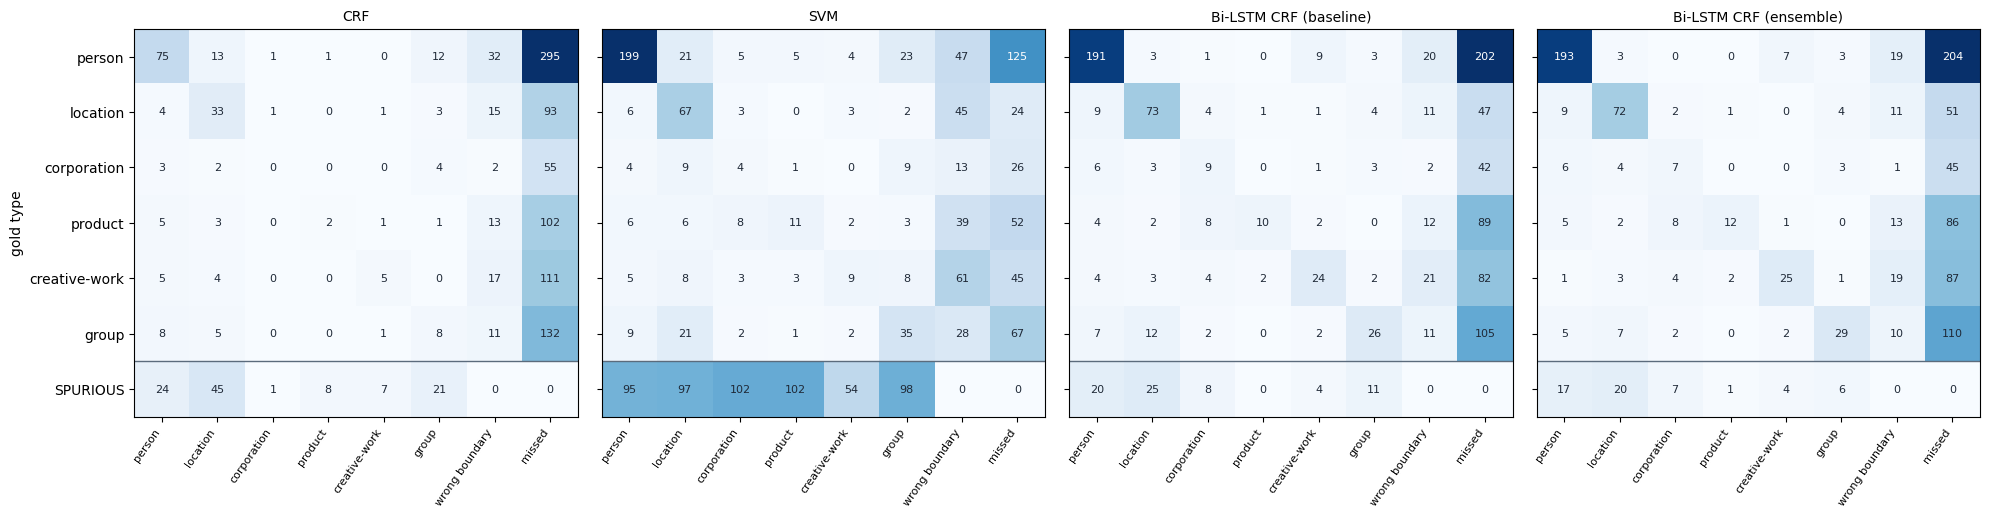

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=True)
for ax, m in zip(axes, MODELS):
    M, rows_, cols_ = type_confusion(test, preds[m]); ax.imshow(M, cmap="Blues", vmin=0, vmax=max(M.max(), 1)); ax.grid(False)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]): ax.text(j, i, M[i, j], ha="center", va="center", fontsize=8, color="white" if M[i, j] > 0.55 * M.max() else "#1F2937")
    ax.set_xticks(range(len(cols_))); ax.set_xticklabels(cols_, rotation=55, ha="right", fontsize=8); ax.set_title(m, fontsize=10); ax.axhline(5.5, color="#5B6B7C", lw=1)
axes[0].set_yticks(range(len(rows_))); axes[0].set_yticklabels(rows_); axes[0].set_ylabel("gold type"); plt.tight_layout(); plt.show()

### Where the models succeed and fail
Recall of gold entities by novelty (seen = the lowercased surface form is an entity in the **train** file), capitalization and length.

In [12]:
seen = {" ".join(x["tokens"][b:e + 1]).lower() for x in splits["train"] for _, b, e in get_entities(x["labels"])}
groups = {"seen in train": [], "unseen": [], "all tokens capitalized": [], "some lowercase token": [], "1 token": [], "2+ tokens": []}
for i, x in enumerate(test):
    for (t, b, e) in get_entities(x["labels"]):
        toks = x["tokens"][b:e + 1]; surf = " ".join(toks).lower(); cap = all(w[:1].isupper() or not w[:1].isalpha() for w in toks)
        for g in (("seen in train" if surf in seen else "unseen"), ("all tokens capitalized" if cap else "some lowercase token"), ("1 token" if e == b else "2+ tokens")): groups[g].append((i, (t, b, e)))
rec = {m: {g: round(100 * np.mean([ent in set(get_entities(preds[m][i])) for i, ent in items]), 1) for g, items in groups.items()} for m in MODELS}
display(pd.concat([pd.DataFrame(rec), pd.Series({g: len(v) for g, v in groups.items()}, name="n gold")], axis=1))

,CRF,SVM,Bi-LSTM CRF (baseline),Bi-LSTM CRF (ensemble),n gold
seen in train,20.8,66.7,70.8,62.5,24
unseen,11.2,29.3,30.0,30.6,1055
all tokens capitalized,14.8,38.5,39.4,40.4,800
some lowercase token,1.8,6.1,6.5,5.4,279
1 token,9.5,36.8,32.0,32.3,718
2+ tokens,15.2,16.9,28.5,29.4,361


### Examples of correct and incorrect predictions (test set)

In [13]:
def spans(x, labels): return [(t, " ".join(x["tokens"][b:e + 1])) for t, b, e in get_entities(labels)]
def exact(i, m): return set(get_entities(preds[m][i])) == set(get_entities(test[i]["labels"]))
short = [i for i, x in enumerate(test) if 0 < len(get_entities(x["labels"])) and len(x["tokens"]) <= 18]
for m in MODELS:
    ok = [i for i in short if exact(i, m)][:2]; bad = [i for i in short if not exact(i, m)][:2]
    for tag, ids in (("CORRECT", ok), ("INCORRECT", bad)):
        for i in ids: print(f"[{m} | {tag}] {' '.join(test[i]['tokens'])}\n    gold: {spans(test[i], test[i]['labels'])}\n    pred: {spans(test[i], preds[m][i])}")

[CRF | CORRECT] He said the soldiers deployed in Siachen are being provided pre-fabricated insulated shelters .
    gold: [('location', 'Siachen')]
    pred: [('location', 'Siachen')]
[CRF | CORRECT] KEINE BREMSEN !
    gold: [('person', 'KEINE BREMSEN')]
    pred: [('person', 'KEINE BREMSEN')]
[CRF | INCORRECT] Visuals of the avalanche site in Gurez sector .
    gold: [('location', 'Gurez sector')]
    pred: [('location', 'Gurez')]
[CRF | INCORRECT] ( Source : ANI ) Visuals of the avalanche site in Gurez sector .
    gold: [('group', 'ANI'), ('location', 'Gurez sector')]
    pred: [('location', 'Gurez')]
[SVM | CORRECT] Road and airport closure isolate Srinagar as avalanche risk remains high
    gold: [('location', 'Srinagar')]
    pred: [('location', 'Srinagar')]
[SVM | CORRECT] He said the soldiers deployed in Siachen are being provided pre-fabricated insulated shelters .
    gold: [('location', 'Siachen')]
    pred: [('location', 'Siachen')]
[SVM | INCORRECT] Visuals of the avalanc

## 7. Summary
* With Twitter-only training and seed 42, the Bi-LSTM CRF baseline is well ahead of the SVM and CRF.
* The four single changes looked better on dev but not on test, and the decoding shift tuned on dev lowered test F1. The single model chosen by dev is worse than the baseline on test.
* The ensemble of the six seed-42 models is the only change that rose on both dev and test; its gain is within the noise of one seed (see the bootstrap interval).
* Unseen entities, entities with lowercase tokens and the types corporation, product, creative-work and group remain hard.
* Training data are **not** mixed across sources yet; that is the next step. Deviations and bug fixes are listed in the report (Appendix B).